In [1]:
from TableToDict import GetDFv2, GetDF, DisplayColumns
from HuRI import GetHuRI
#from ccsblib import  huri
from  Load_CCSB_Data import GetOrfMapping
import pandas as pd
import numpy as np

from matplotlib import pyplot as plt
import seaborn as sns

from PandasToMySQL import MakeSummaryTable

%matplotlib inline
%config InlineBackend.figure_format='retina'

pd.options.display.max_rows = 1000
pd.options.display.max_columns = 60

In [2]:
from glob import glob

## qY2H data

In [3]:
PRS_RRS_df = pd.read_csv('../../../MasterThesis_Gaspard/data/PRS_RRS.csv',sep='\t')
PRS_RRS_df.drop(columns=['Unnamed: 0','pair'],inplace=True)
PRS_RRS_df['pair'] = [tuple(sorted([ad,db])) for ad, db  in zip(PRS_RRS_df.ad_orf_id, PRS_RRS_df.db_orf_id)]

def calculate_score_cumulative(LW,LWH1,LWH10,LWH25,LWA,LWAH1,LW_ead,LWH1_ead,LWH10_ead,LWH25_ead,LWA_ead,LWAH1_ead):
    '''
    #1|all scores are normalized by LW level or NA if LW = 0 
    #2|NA if AA on most stringent detected level, otherwise normalized score
    #3|final score = sum of all processed GS
    '''
    res = np.nan
    
    ead_scores = [LWH1_ead,LWH10_ead,LWH25_ead,LWA_ead,LWAH1_ead]
    scores = [LWH1,LWH10,LWH25,LWA,LWAH1]
    
    if LW > 0 and LW_ead > 0: 
        
        scores = [s/LW for s in scores]
        ead_scores = [s/LW for s in ead_scores]
        
        aa = False
        for aa,s in zip(ead_scores[::-1], scores[::-1]):
            if aa >= s and aa > 0:
                res = np.nan
                aa = True
                break
            elif s > 0 and aa == 0:
                break
                
        if aa == False:

            scores = [s - ead_s for s,ead_s in zip(scores, ead_scores)]
            scores = [s for s in scores if s == s]

            res = sum(scores)/len(scores)

            if res < 0:
                res = 0
        
    return res

PRS_RRS_df['cum_score'] = [calculate_score_cumulative(LW,LWH1,LWH10,LWH25,LWA,LWAH1,LW_ead,LWH1_ead,LWH10_ead,LWH25_ead,LWA_ead,LWAH1_ead) for LW,LWH1,LWH10,LWH25,LWA,LWAH1,LW_ead,LWH1_ead,LWH10_ead,LWH25_ead,LWA_ead,LWAH1_ead in zip(PRS_RRS_df.LW,PRS_RRS_df.LWH1,PRS_RRS_df.LWH10,PRS_RRS_df.LWH25,PRS_RRS_df.LWA,PRS_RRS_df.LWAH1,PRS_RRS_df.LW_ead,PRS_RRS_df.LWH1_ead,PRS_RRS_df.LWH10_ead,PRS_RRS_df.LWH25_ead,PRS_RRS_df.LWA_ead,PRS_RRS_df.LWAH1_ead)]
#PRS_RRS_df['orient'] = PRS_RRS_df.db_source_plate.apply(lambda x: 'DBA_ADB' if )

qY2H_d = {'DBA_ADB':dict(),'DBB_ADA':dict()}
for s,p, pair in zip(PRS_RRS_df.cum_score, PRS_RRS_df.db_source_plate, PRS_RRS_df.pair):
    k = 'DBA_ADB' if p[4] == 'A' else 'DBB_ADA'
    qY2H_d[k][pair] = s



PRS_RRS_df.head()

,ad_orf_id,db_orf_id,ad_symbol,db_symbol,retest_pla,retest_pos,retest_batch,db_source_plate,LW,LWH1,LWH10,LWH25,LWA,LWAH1,cat,LW_ead,LWH1_ead,LWH10_ead,LWH25_ead,LWA_ead,LWAH1_ead,pair,cum_score
0,7186,3174,ZC3HC1,PDHB,2,G01,VUSPRSRRS,db_1A_RRS,4.0,0.0,0.0,0.0,0.0,0.0,RRS,4.0,0.0,0.0,0.0,0.0,0.0,"(3174, 7186)",0.0
1,5046,273,NQO2,FKBP3,2,A02,VUSPRSRRS,db_1A_RRS,4.0,0.0,0.0,0.0,0.0,0.0,RRS,4.0,0.0,0.0,0.0,0.0,0.0,"(273, 5046)",0.0
2,8764,5114,BOC,RAB3B,2,C02,VUSPRSRRS,db_1A_RRS,4.0,0.0,0.0,0.0,0.0,0.0,RRS,4.0,0.0,0.0,0.0,0.0,0.0,"(5114, 8764)",0.0
3,8327,1108,GRAP2,LCP2,2,D02,VUSPRSRRS,db_1A_PRS,4.0,4.0,4.0,4.0,2.0,2.0,PRS,4.0,0.0,0.0,0.0,0.0,0.0,"(1108, 8327)",0.8
4,6601,5664,LSM2,LSM3,2,E02,VUSPRSRRS,db_1A_PRS,4.0,4.0,4.0,4.0,0.0,0.0,PRS,4.0,0.0,0.0,0.0,0.0,0.0,"(5664, 6601)",0.6


In [4]:
PRS_RRS_df.db_source_plate.value_counts()

db_1A_RRS    39
db_2B_RRS    39
db_2A_RRS    39
db_1B_RRS    39
db_1A_PRS    30
db_2B_PRS    30
db_2A_PRS    30
db_1B_PRS    30
Name: db_source_plate, dtype: int64

## Choi data

In [5]:
prs_rrs_raw_old26_df = pd.read_excel('../../../MasterThesis_Gaspard/data/hsPRS_RRS-v2-all assays.xlsx', skiprows=1)
PRS_RRS_cat_d = dict(zip(prs_rrs_raw_old26_df.Linked, prs_rrs_raw_old26_df.Category))
prs_rrs_raw_df = pd.read_csv('../../../MasterThesis_Gaspard/data/Assayome 42 assay versions.csv', sep=',')
prs_rrs_raw_df['Category'] = prs_rrs_raw_df.Gene.map(PRS_RRS_cat_d)
prs_rrs_raw_df.rename(columns={c:'_'.join(w for w in c.replace('-','_').split()) for c in prs_rrs_raw_df.columns}, inplace=True)
prs_rrs_raw_df['pair'] = prs_rrs_raw_df.Gene.apply(lambda x: tuple(sorted(x.split('+'))))

yN2H_d = dict(zip(prs_rrs_raw_df.pair, prs_rrs_raw_df.YN2H_N1N2_XY))

prs_rrs_raw_df.head()

,Gene,cBRET_N1N2_XY,cBRET_N1C2_XY,cBRET_C1N2_XY,cBRET_C1C2_XY,cBRET_N1N2_YX,cBRET_N1C2_YX,cBRET_C1N2_YX,cBRET_C1C2_YX,cLuC_N1N2_XY,cLuC_N1C2_XY,cLuC_C1N2_XY,cLuC_C1C2_XY,cLuC_N1N2_YX,cLuC_C1N2_YX,cLuC_N1C2_YX,cLuC_C1C2_YX,Y2H_N1N2_XY,Y2H_N1N2_YX,MAPPIT_N1N2_XY,MAPPIT_N1N2_YX,KISS_N1N2_XY,KISS_N1C2_XY,NanoBiT_N1N2_XY,NanoBiT_C1C2_XY,NanoBiT_N1C2_XY,NanoBiT_C1N2_XY,GPCA_N1N2_XY,GPCA_C1C2_XY,GPCA_N1C2_XY,GPCA_C1N2_XY,YN2H_N1N2_XY,YN2H_C1C2_XY,YN2H_N1C2_XY,YN2H_C1N2_XY,MN2H_N1N2_XY,MN2H_C1C2_XY,MN2H_N1C2_XY,MN2H_C1N2_XY,VN2H_N1N2_XY,VN2H_C1C2_XY,VN2H_N1C2_XY,VN2H_C1N2_XY,Category,pair
0,LCP2+NCK1,-0.4103,-0.4745,-0.2690,-0.8350,-0.5398,-1.5568,-0.5803,-0.2830,-0.2955,-0.3742,-0.3540,-0.3690,-0.3967,-0.3305,-0.3532,-0.2904,-0.3065,-0.2923,-0.2826,-0.2370,-0.2308,0.4405,-0.2420,-0.2725,-0.2270,-0.2296,-0.2606,-0.3152,-0.2687,-0.2799,0.0520,0.5481,0.3068,0.1101,-0.2172,-0.2282,-0.1991,-0.2041,1.7948,0.0444,3.8768,0.1704,PRS,"(LCP2, NCK1)"
1,LCP2+GRAP2,0.6395,1.9487,0.6675,1.6086,0.4949,0.9931,0.2389,0.6432,0.3820,1.9108,1.6136,2.8257,0.3472,0.3394,0.0463,-0.0676,3.2179,-0.2923,0.4316,-0.2702,-0.3208,-0.1359,-0.2420,-0.1583,-0.0130,-0.2231,0.2157,0.5686,3.5076,2.7149,-0.1094,-0.0207,0.2410,-0.1024,0.6125,0.7454,0.5372,0.5606,0.4325,-0.0687,2.9013,-0.1924,PRS,"(GRAP2, LCP2)"
2,LSM3+LSM2,5.9142,8.1645,7.6331,6.8810,5.3733,7.8651,3.7128,5.2898,1.6134,2.9846,3.4506,3.5430,2.6076,5.2261,4.5667,2.0423,3.2179,3.3742,8.3894,7.2090,3.1449,6.2960,0.1181,1.1224,-0.0316,5.3532,0.5281,1.0751,2.2879,1.9297,0.0012,0.2928,4.3892,-0.0688,0.2476,0.3227,0.9361,0.0729,3.0408,0.7131,1.1883,0.5261,PRS,"(LSM2, LSM3)"
3,IFIT1+EIF3E,-0.7900,-0.7920,NaN,NaN,-0.6415,-1.3403,-0.7140,-0.3990,-0.2955,-0.3722,NaN,NaN,-0.3016,-0.3300,-0.2623,-0.2904,-0.3065,-0.2923,-0.2941,-0.2472,-0.2217,-0.1051,-0.2389,-0.2696,-0.2270,-0.2309,-0.2695,-0.3151,-0.2676,-0.2824,-0.1514,-0.1060,-0.0787,-0.1309,-0.2796,-0.2314,-0.2027,-0.2697,-0.5131,-0.1641,-0.3865,-0.2431,PRS,"(EIF3E, IFIT1)"
4,PSMD4+RAD23A,0.6412,-0.2221,0.7230,-0.3891,-0.1840,-0.2349,-0.1898,-0.4047,-0.2150,-0.3722,-0.3145,-0.3250,-0.3016,-0.3300,-0.2623,-0.2802,-0.3065,-0.2923,-0.3061,-0.1457,-0.1754,-0.3914,-0.1908,-0.2652,-0.4130,-0.2218,-0.1994,-0.3100,-0.2639,-0.0589,-0.1313,-0.1329,-0.2668,0.1613,0.9954,-0.1794,-0.1460,1.2245,4.8518,2.0832,3.5596,6.2446,PRS,"(PSMD4, RAD23A)"


## Previous data (New clones)

In [6]:
nano_score = pd.read_csv('data/hPRSRRSv2_nanoluc_scores_20221115.tsv', sep='\t')

nano_orient_d = {9: 'ADA_DBB',
10: 'ADB_DBA',
11: 'ADA_DBB',
12: 'ADB_DBA'}

nano_score['orient'] = nano_score.plate.apply(lambda x: nano_orient_d[int(x.split('_')[0])])
nano_score['pla'] = nano_score.plate.apply(lambda x: int(x.split('_')[2][0]))

nano_score_d = {(orient,pla,well):(score, score_control,nlr,call_0rrs) for i,(category,plate,well,symbol_a,symbol_b,score,score_control,nlr,call_0rrs,orient,pla) in nano_score.iterrows()}

nano_score.head()

,category,plate,well,symbol_a,symbol_b,score,score_control,nlr,call_0rrs,orient,pla
0,PRS,10_R2HMet_1BxBK100_1A,A01,LCP2,NCK1,79020,19513,4.049608,1,ADB_DBA,1
1,RRS,10_R2HMet_1BxBK100_1A,A02,FKBP3,NQO2,56210,23202,2.422636,0,ADB_DBA,1
2,PRS,10_R2HMet_1BxBK100_1A,A04,ORC2,MCM10,59703,35570,1.678465,0,ADB_DBA,1
3,PRS,10_R2HMet_1BxBK100_1A,A05,BDNF,NTF4,87928,35219,2.496607,1,ADB_DBA,1
4,RRS,10_R2HMet_1BxBK100_1A,A06,RGR,ABCF3,55805,31364,1.779269,0,ADB_DBA,1


## New data

In [7]:
res = {}
for file in glob('data/20230206 hPRSRRSv2 pilot/*.xls'):

    df = pd.read_excel(file, skiprows=10, skipfooter=35, engine='xlrd')
    df.rename(columns={c:i+1 for i,c in enumerate(df.columns)}, inplace=True)
    pla = file.split('_')[-1][:-4]
    value_d = dict()
    for l, (i, row) in zip(['A','B','C','D','E','F','G','H'], df.iterrows()):
        for i, value in enumerate(row):
            key = (pla,f'{l}{str(i+1).zfill(2)}')
            res[key] = value

*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'


In [8]:
prsrrsv2 = GetDF('prsrrsv2','prsrrsv2')
col = ['orf_ida', 'symbol_a','orf_idb', 'symbol_b','category', 'plate', 'well']
prsrrsv2 = prsrrsv2[prsrrsv2.is_v2==1][col].copy()

prsrrsv2['DBA_ADB'] = [res['DB1AxAD1B',well] if pla == 1 else res['DB2AxAD2B',well] for pla,well in zip(prsrrsv2.plate, prsrrsv2.well)]
prsrrsv2['DBA_EAD'] = [res['DB1AxemptyAD',well] if pla == 1 else res['DB2AxemptyAD',well] for pla,well in zip(prsrrsv2.plate, prsrrsv2.well)]
prsrrsv2['DBB_ADA'] = [res['DB1BxAD1A',well] if pla == 1 else res['DB2BxAD2A',well] for pla,well in zip(prsrrsv2.plate, prsrrsv2.well)]
prsrrsv2['DBB_EAD'] = [res['DB1BxemptyAD',well] if pla == 1 else res['DB2BxemptyAD',well] for pla,well in zip(prsrrsv2.plate, prsrrsv2.well)]

prsrrsv2['DBA_ADB_fail'] = [score < 5000 or ead_score < 5000 for score, ead_score in zip(prsrrsv2.DBA_ADB, prsrrsv2.DBA_EAD)]
prsrrsv2['DBB_ADA_fail'] = [score < 5000 or ead_score < 5000 for score, ead_score in zip(prsrrsv2.DBB_ADA, prsrrsv2.DBB_EAD)]

prsrrsv2['NLR_DBA_ADB'] = [np.log2(DBA_ADB/DBA_EAD) if not fail else np.nan for DBA_ADB,DBA_EAD, fail in zip(prsrrsv2.DBA_ADB, prsrrsv2.DBA_EAD, prsrrsv2.DBA_ADB_fail)]
prsrrsv2['NLR_DBB_ADA'] = [np.log2(DBB_ADA/DBB_EAD) if not fail else np.nan for DBB_ADA,DBB_EAD, fail in zip(prsrrsv2.DBB_ADA, prsrrsv2.DBB_EAD, prsrrsv2.DBB_ADA_fail)]

prsrrsv2['DBA_ADB_old'] = [nano_score_d['ADB_DBA',pla,well][0] for pla,well in zip(prsrrsv2.plate, prsrrsv2.well)]
prsrrsv2['DBA_EAD_old'] = [nano_score_d['ADB_DBA',pla,well][1] for pla,well in zip(prsrrsv2.plate, prsrrsv2.well)]
prsrrsv2['DBB_ADA_old'] = [nano_score_d['ADA_DBB',pla,well][0] for pla,well in zip(prsrrsv2.plate, prsrrsv2.well)]
prsrrsv2['DBB_EAD_old'] = [nano_score_d['ADA_DBB',pla,well][1] for pla,well in zip(prsrrsv2.plate, prsrrsv2.well)]

prsrrsv2['DBA_ADB_fail_old'] = [score < 5000 or ead_score < 5000 for score, ead_score in zip(prsrrsv2.DBA_ADB_old, prsrrsv2.DBA_EAD_old)]
prsrrsv2['DBB_ADA_fail_old'] = [score < 5000 or ead_score < 5000 for score, ead_score in zip(prsrrsv2.DBB_ADA_old, prsrrsv2.DBB_EAD_old)]

prsrrsv2['NLR_DBA_ADB_old'] = [np.log2(DBA_ADB/DBA_EAD) if not fail else np.nan for DBA_ADB,DBA_EAD, fail in zip(prsrrsv2.DBA_ADB_old, prsrrsv2.DBA_EAD_old, prsrrsv2.DBA_ADB_fail_old)]
prsrrsv2['NLR_DBB_ADA_old'] = [np.log2(DBB_ADA/DBB_EAD) if not fail else np.nan for DBB_ADA,DBB_EAD, fail in zip(prsrrsv2.DBB_ADA_old, prsrrsv2.DBB_EAD_old, prsrrsv2.DBB_ADA_fail_old)]

prsrrsv2['qY2H_DBA_ADB'] = [qY2H_d['DBA_ADB'][tuple(sorted([oa,ob]))] for oa, ob in zip(prsrrsv2.orf_ida, prsrrsv2.orf_idb)]
prsrrsv2['qY2H_DBB_ADA'] = [qY2H_d['DBB_ADA'][tuple(sorted([oa,ob]))] for oa, ob in zip(prsrrsv2.orf_ida, prsrrsv2.orf_idb)]

DBA_ADB_rrs_nlr = prsrrsv2[prsrrsv2.category == 'RRS'].NLR_DBA_ADB
DBB_ADA_rrs_nlr = prsrrsv2[prsrrsv2.category == 'RRS'].NLR_DBB_ADA

prsrrsv2['zNLR_DBA_ADB'] = prsrrsv2.NLR_DBA_ADB.apply(lambda x: (x-np.mean(DBA_ADB_rrs_nlr))/np.std(DBA_ADB_rrs_nlr))
prsrrsv2['zNLR_DBB_ADA'] = prsrrsv2.NLR_DBB_ADA.apply(lambda x: (x-np.mean(DBB_ADA_rrs_nlr))/np.std(DBB_ADA_rrs_nlr))

DBA_ADB_nlr_detection = (2.326 * np.std(DBA_ADB_rrs_nlr)) + np.mean(DBA_ADB_rrs_nlr)
DBB_ADA_nlr_detection = (2.326 * np.std(DBB_ADA_rrs_nlr)) + np.mean(DBB_ADA_rrs_nlr)
print(DBA_ADB_nlr_detection, DBB_ADA_nlr_detection)

prsrrsv2['dqY2H_DBA_ADB'] = prsrrsv2.qY2H_DBA_ADB.apply(lambda x: 1 if x > 0 else 0 if x == x else np.nan)
prsrrsv2['dqY2H_DBB_ADA'] = prsrrsv2.qY2H_DBB_ADA.apply(lambda x: 1 if x > 0 else 0 if x == x else np.nan)

prsrrsv2['dnY2H_DBA_ADB'] = prsrrsv2.NLR_DBA_ADB.apply(lambda x: 1 if x > DBA_ADB_nlr_detection else 0 if x == x else np.nan)
prsrrsv2['dnY2H_DBB_ADA'] = prsrrsv2.NLR_DBB_ADA.apply(lambda x: 1 if x > DBA_ADB_nlr_detection else 0 if x == x else np.nan)

prsrrsv2.head()

2.018286531808936 1.7883275720731053


,orf_ida,symbol_a,orf_idb,symbol_b,category,plate,well,DBA_ADB,DBA_EAD,DBB_ADA,DBB_EAD,DBA_ADB_fail,DBB_ADA_fail,NLR_DBA_ADB,NLR_DBB_ADA,DBA_ADB_old,DBA_EAD_old,DBB_ADA_old,DBB_EAD_old,DBA_ADB_fail_old,DBB_ADA_fail_old,NLR_DBA_ADB_old,NLR_DBB_ADA_old,qY2H_DBA_ADB,qY2H_DBB_ADA,zNLR_DBA_ADB,zNLR_DBB_ADA,dqY2H_DBA_ADB,dqY2H_DBB_ADA,dnY2H_DBA_ADB,dnY2H_DBB_ADA
0,1108,LCP2,5001,NCK1,PRS,1,A01,201648,154525,213255,195766,False,False,0.383999,0.123449,79020,19513,58912,20797,False,False,2.017782,1.502186,0.0,0.0,0.077138,-0.434010,0.0,0.0,0.0,0.0
1,617,SHMT2,4447,STAC3,RRS,1,D01,208868,221298,220,184874,False,True,-0.083399,NaN,78181,41659,57049,29502,False,False,0.908190,0.951389,0.0,0.0,-0.566025,NaN,0.0,0.0,0.0,NaN
2,3535,EMD,5887,ARMC1,RRS,1,F01,176809,209620,202207,223298,False,False,-0.245585,-0.143137,65905,33446,68944,45088,False,False,0.978554,0.612681,0.0,0.0,-0.789201,-0.875953,0.0,0.0,0.0,0.0
3,3174,PDHB,7186,ZC3HC1,RRS,1,G01,224657,122075,281304,137698,False,False,0.879956,1.030622,76461,39590,72988,36882,False,False,0.949588,0.984742,0.0,0.0,0.759600,1.069888,0.0,0.0,0.0,0.0
4,273,FKBP3,5046,NQO2,RRS,1,A02,157736,189196,130420,150440,False,False,-0.262370,-0.206023,56210,23202,24610,16202,False,False,1.276578,0.603073,0.0,0.0,-0.812298,-0.980204,0.0,0.0,0.0,0.0


(0.0, 120.0)

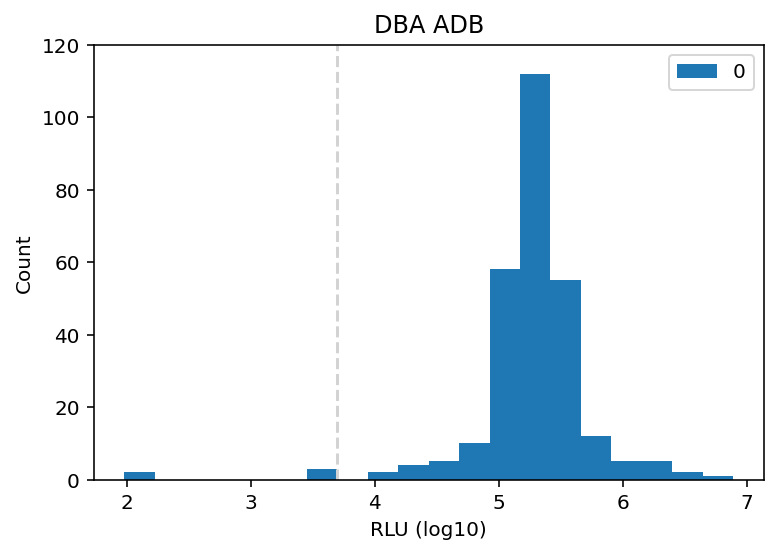

In [9]:
pd.DataFrame(prsrrsv2.DBA_ADB.apply(np.log10).tolist() + prsrrsv2.DBA_EAD.apply(np.log10).tolist()).plot.hist(bins=20)
plt.xlabel('RLU (log10)')
plt.ylabel('Count')
plt.title('DBA ADB')
plt.vlines(ymin=0,ymax=120,x=np.log10(5000), linestyles='--', color='lightgrey')
plt.ylim(0,120)

In [10]:
pd.DataFrame(prsrrsv2.DBA_ADB.apply(np.log10).tolist() + prsrrsv2.DBA_EAD.apply(np.log10).tolist()).median()

0    5.316725
dtype: float64

(0.0, 120.0)

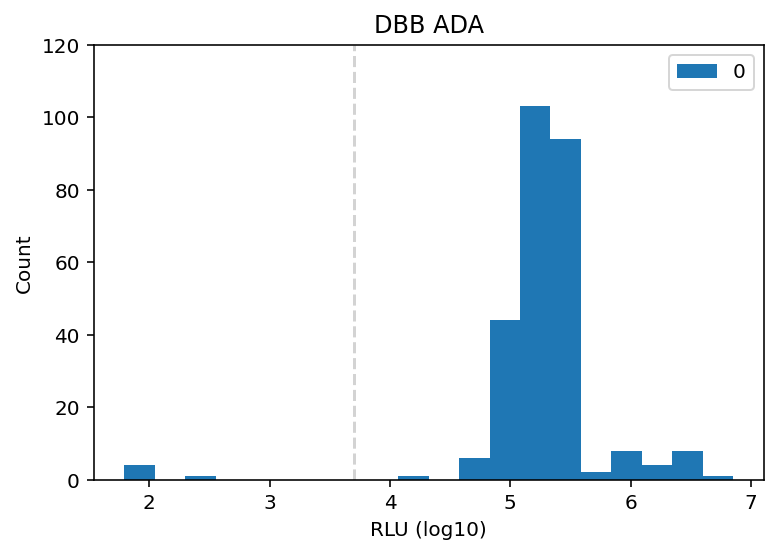

In [11]:
pd.DataFrame(prsrrsv2.DBB_ADA.apply(np.log10).tolist() + prsrrsv2.DBB_EAD.apply(np.log10).tolist()).plot.hist(bins=20)
plt.xlabel('RLU (log10)')
plt.ylabel('Count')
plt.title('DBB ADA')
plt.vlines(ymin=0,ymax=120,x=np.log10(5000), linestyles='--', color='lightgrey')
plt.ylim(0,120)

In [12]:
pd.DataFrame(prsrrsv2.DBB_ADA.apply(np.log10).tolist() + prsrrsv2.DBB_EAD.apply(np.log10).tolist()).median()

0    5.296873
dtype: float64

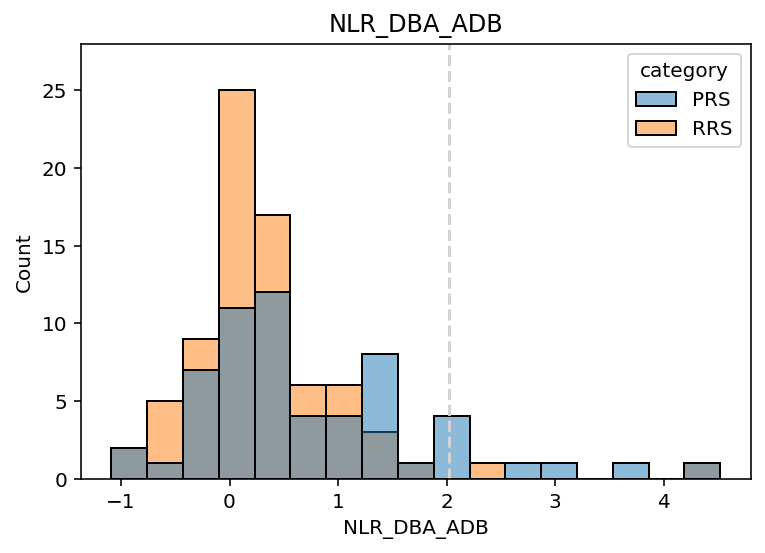

In [15]:
plt.figure()
plt.vlines(ymin=0, ymax=28, x=DBA_ADB_nlr_detection, linestyles='--', color='lightgrey')
plt.ylim(0,28)
sns.histplot(data=prsrrsv2, x='NLR_DBA_ADB', hue='category', legend=True);
plt.title('NLR_DBA_ADB');

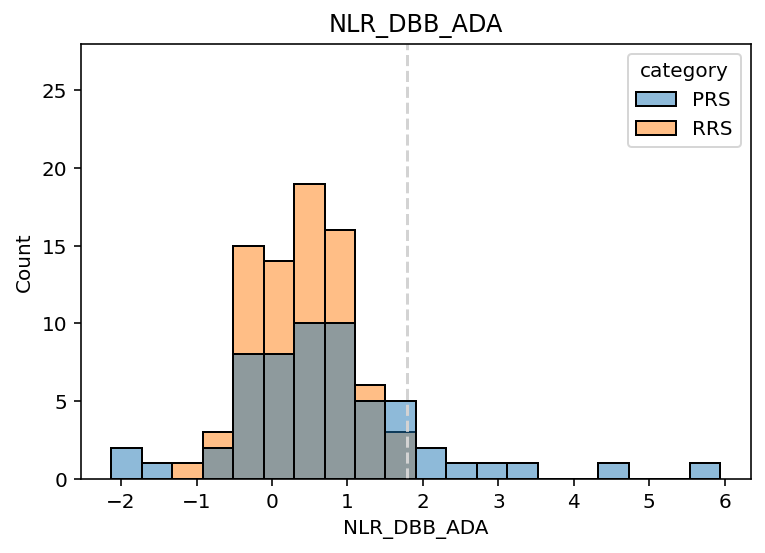

In [16]:
plt.figure()
plt.vlines(ymin=0, ymax=28, x=DBB_ADA_nlr_detection, linestyles='--', color='lightgrey')
plt.ylim(0,28)
sns.histplot(data=prsrrsv2, x='NLR_DBB_ADA', hue='category', legend=True);
plt.title('NLR_DBB_ADA');

In [17]:
prsrrsv2[prsrrsv2.NLR_DBA_ADB_old < -3]

,orf_ida,symbol_a,orf_idb,symbol_b,category,plate,well,DBA_ADB,DBA_EAD,DBB_ADA,DBB_EAD,DBA_ADB_fail,DBB_ADA_fail,NLR_DBA_ADB,NLR_DBB_ADA,DBA_ADB_old,DBA_EAD_old,DBB_ADA_old,DBB_EAD_old,DBA_ADB_fail_old,DBB_ADA_fail_old,NLR_DBA_ADB_old,NLR_DBB_ADA_old,qY2H_DBA_ADB,qY2H_DBB_ADA,zNLR_DBA_ADB,zNLR_DBB_ADA,dqY2H_DBA_ADB,dqY2H_DBB_ADA,dnY2H_DBA_ADB,dnY2H_DBB_ADA


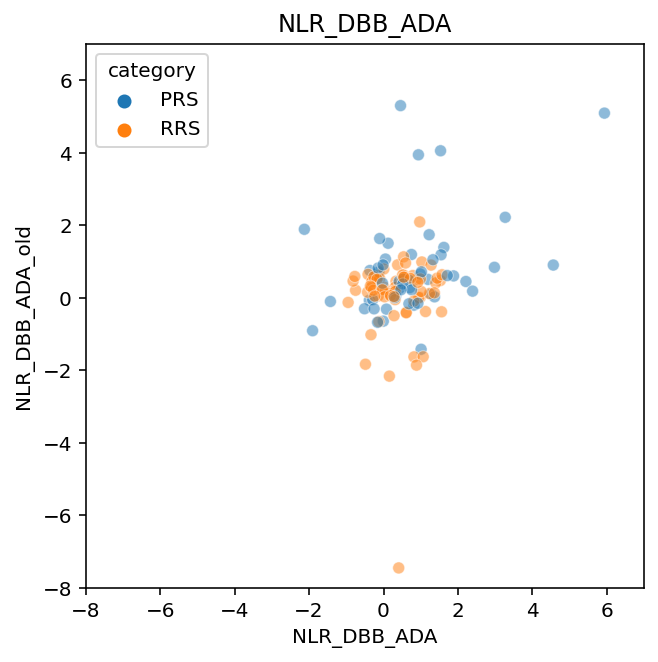

In [18]:
plt.figure(figsize=(5,5))
sns.scatterplot(data=prsrrsv2, x='NLR_DBB_ADA', y='NLR_DBB_ADA_old', hue='category', alpha=.5)

plt.xlim(-8,7)
plt.ylim(-8,7)
plt.title('NLR_DBB_ADA')
plt.show()



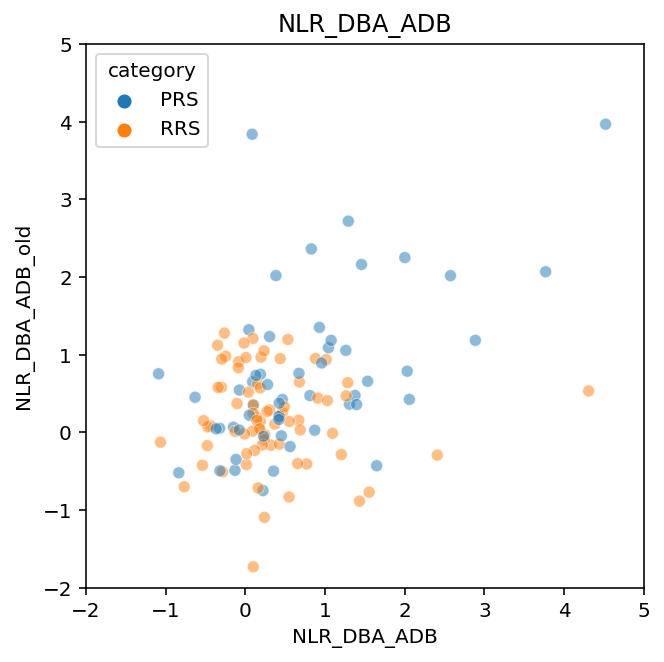

In [19]:
plt.figure(figsize=(5,5))
sns.scatterplot(data=prsrrsv2, x='NLR_DBA_ADB', y='NLR_DBA_ADB_old', hue='category', alpha=.5)

plt.xlim(-2,5)
plt.ylim(-2,5)
plt.title('NLR_DBA_ADB')
plt.show()




In [20]:
np.log2(1263343/430493)

1.5531847026362327

In [21]:
1263343/430493

2.9346423751373427

## qY2H comparisons

In [22]:
prsrrsv2.head()

,orf_ida,symbol_a,orf_idb,symbol_b,category,plate,well,DBA_ADB,DBA_EAD,DBB_ADA,DBB_EAD,DBA_ADB_fail,DBB_ADA_fail,NLR_DBA_ADB,NLR_DBB_ADA,DBA_ADB_old,DBA_EAD_old,DBB_ADA_old,DBB_EAD_old,DBA_ADB_fail_old,DBB_ADA_fail_old,NLR_DBA_ADB_old,NLR_DBB_ADA_old,qY2H_DBA_ADB,qY2H_DBB_ADA,zNLR_DBA_ADB,zNLR_DBB_ADA,dqY2H_DBA_ADB,dqY2H_DBB_ADA,dnY2H_DBA_ADB,dnY2H_DBB_ADA
0,1108,LCP2,5001,NCK1,PRS,1,A01,201648,154525,213255,195766,False,False,0.383999,0.123449,79020,19513,58912,20797,False,False,2.017782,1.502186,0.0,0.0,0.077138,-0.434010,0.0,0.0,0.0,0.0
1,617,SHMT2,4447,STAC3,RRS,1,D01,208868,221298,220,184874,False,True,-0.083399,NaN,78181,41659,57049,29502,False,False,0.908190,0.951389,0.0,0.0,-0.566025,NaN,0.0,0.0,0.0,NaN
2,3535,EMD,5887,ARMC1,RRS,1,F01,176809,209620,202207,223298,False,False,-0.245585,-0.143137,65905,33446,68944,45088,False,False,0.978554,0.612681,0.0,0.0,-0.789201,-0.875953,0.0,0.0,0.0,0.0
3,3174,PDHB,7186,ZC3HC1,RRS,1,G01,224657,122075,281304,137698,False,False,0.879956,1.030622,76461,39590,72988,36882,False,False,0.949588,0.984742,0.0,0.0,0.759600,1.069888,0.0,0.0,0.0,0.0
4,273,FKBP3,5046,NQO2,RRS,1,A02,157736,189196,130420,150440,False,False,-0.262370,-0.206023,56210,23202,24610,16202,False,False,1.276578,0.603073,0.0,0.0,-0.812298,-0.980204,0.0,0.0,0.0,0.0


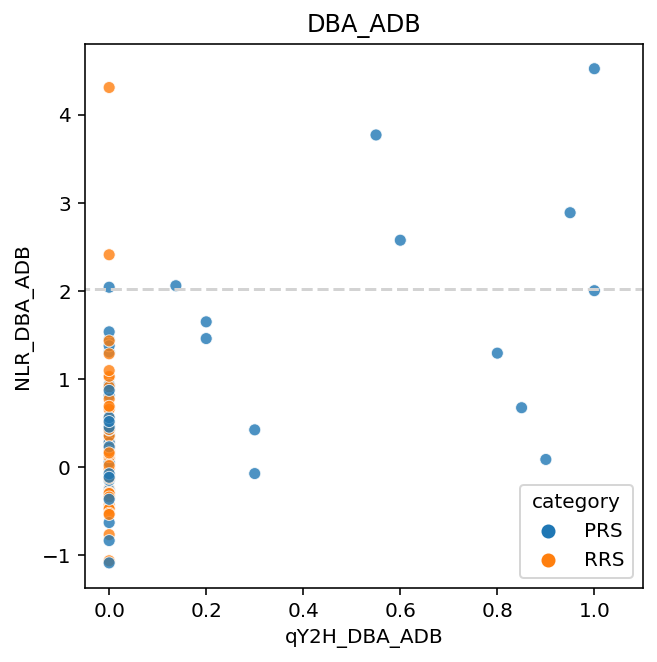

In [23]:
plt.figure(figsize=(5,5))

plt.title('DBA_ADB')
sns.scatterplot(data=prsrrsv2, x='qY2H_DBA_ADB', y='NLR_DBA_ADB', hue='category', alpha=0.8)
plt.hlines(y=DBA_ADB_nlr_detection, xmin=-1, xmax=2, linestyles='--', color='lightgrey')
plt.xlim(-.05,1.1)

plt.show()

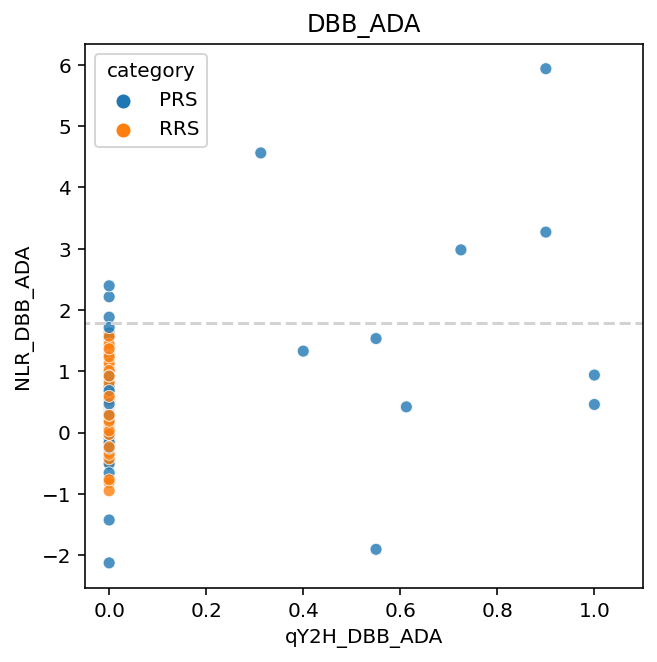

In [24]:
plt.figure(figsize=(5,5))

plt.title('DBB_ADA')
sns.scatterplot(data=prsrrsv2, x='qY2H_DBB_ADA', y='NLR_DBB_ADA', hue='category', alpha=0.8)
plt.hlines(y=DBB_ADA_nlr_detection, xmin=-1, xmax=2, linestyles='--', color='lightgrey')
plt.xlim(-.05,1.1)

plt.show()

## checkerboard

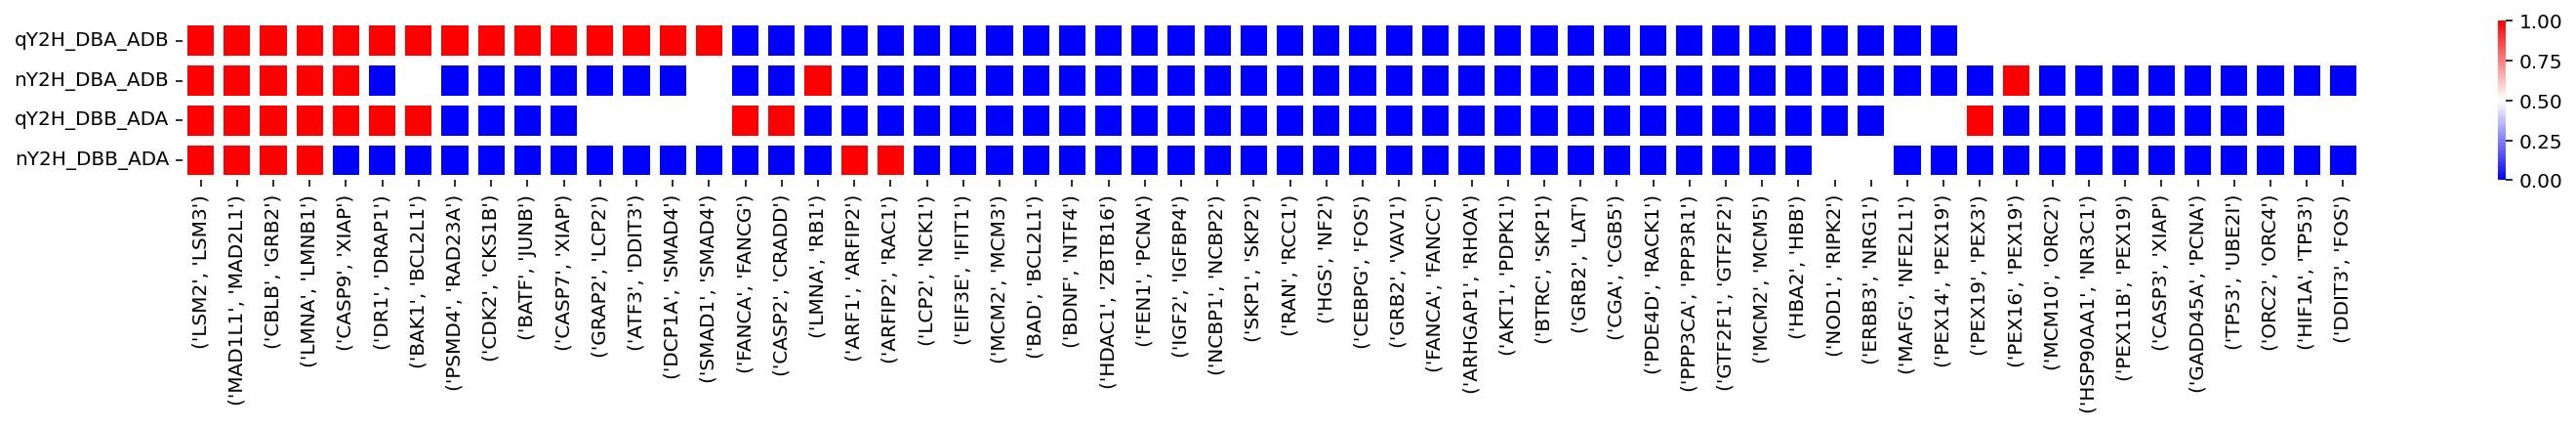

In [54]:
df = prsrrsv2[prsrrsv2.category == 'PRS'].copy()
df['pair']= [tuple(sorted([sa,sb])) for sa,sb in zip(df.symbol_a, df.symbol_b)]
col = ['pair','dqY2H_DBA_ADB', 'dnY2H_DBA_ADB', 'dqY2H_DBB_ADA', 'dnY2H_DBB_ADA']

df = df[col].copy()
df.set_index('pair', inplace=True)
df.rename(columns={c:c[1:] if c != 'pair' else 'pair' for c in df.columns},inplace=True)

df.sort_values(by=['qY2H_DBA_ADB','qY2H_DBB_ADA','nY2H_DBA_ADB','nY2H_DBB_ADA'], ascending=[False,False,False,False], inplace=True)

plt.figure(figsize=(25,1.5))
sns.heatmap(data=df.T, linewidth=5, cmap='bwr')
plt.xlabel('');
plt.show()

In [66]:
prsrrsv2.to_csv('hs_prs_rrs_v2_qY2H_nY2H.csv')

In [65]:
prsrrsv2.head()

,orf_ida,symbol_a,orf_idb,symbol_b,category,plate,well,DBA_ADB,DBA_EAD,DBB_ADA,DBB_EAD,DBA_ADB_fail,DBB_ADA_fail,NLR_DBA_ADB,NLR_DBB_ADA,DBA_ADB_old,DBA_EAD_old,DBB_ADA_old,DBB_EAD_old,DBA_ADB_fail_old,DBB_ADA_fail_old,NLR_DBA_ADB_old,NLR_DBB_ADA_old,qY2H_DBA_ADB,qY2H_DBB_ADA,zNLR_DBA_ADB,zNLR_DBB_ADA,dqY2H_DBA_ADB,dqY2H_DBB_ADA,dnY2H_DBA_ADB,dnY2H_DBB_ADA
0,1108,LCP2,5001,NCK1,PRS,1,A01,201648,154525,213255,195766,False,False,0.383999,0.123449,79020,19513,58912,20797,False,False,2.017782,1.502186,0.0,0.0,0.077138,-0.434010,0.0,0.0,0.0,0.0
1,617,SHMT2,4447,STAC3,RRS,1,D01,208868,221298,220,184874,False,True,-0.083399,NaN,78181,41659,57049,29502,False,False,0.908190,0.951389,0.0,0.0,-0.566025,NaN,0.0,0.0,0.0,NaN
2,3535,EMD,5887,ARMC1,RRS,1,F01,176809,209620,202207,223298,False,False,-0.245585,-0.143137,65905,33446,68944,45088,False,False,0.978554,0.612681,0.0,0.0,-0.789201,-0.875953,0.0,0.0,0.0,0.0
3,3174,PDHB,7186,ZC3HC1,RRS,1,G01,224657,122075,281304,137698,False,False,0.879956,1.030622,76461,39590,72988,36882,False,False,0.949588,0.984742,0.0,0.0,0.759600,1.069888,0.0,0.0,0.0,0.0
4,273,FKBP3,5046,NQO2,RRS,1,A02,157736,189196,130420,150440,False,False,-0.262370,-0.206023,56210,23202,24610,16202,False,False,1.276578,0.603073,0.0,0.0,-0.812298,-0.980204,0.0,0.0,0.0,0.0


## quick analysis

In [60]:
from matplotlib_venn import venn3

In [62]:
alleles = GetDFv2()
alleles['change'] = list(zip(alleles.nt_change, alleles.aa_change))
alleles.head()

,orf_id,nt_change,aa_change,symbol,ensg,entrez,rc4_mut_id,cegs_mut_id,vus_mut_id,rc4_plate,rc4_well,cegs_plate,cegs_well,vus_plate,vus_well,chr,chr_pos_37,chr_pos_38,cv_allele_id,hgmd_id,cv_clinical_significance,cv_phenotypes,cv_phenotype_ids,hgmd_clinical_significance,hgmd_phenotype,clinical_significance,change
0,2,160G>C,Val54Leu,GBA,ENSG00000177628,2629,6.0,NaN,NaN,RC4_Mut_GDEh1026,H01,None,None,None,None,1,155209824,155240033,NaN,CM960691,None,None,None,DM,Gaucher disease,Pathogenic,"(160G>C, Val54Leu)"
1,2,670C>T,Leu224Phe,GBA,ENSG00000177628,2629,73.0,NaN,NaN,RC4_Mut_GDEh1026,E01,None,None,None,None,1,155208016,155238225,NaN,CM057091,None,None,None,DM?,Gaucher disease,Pathogenic,"(670C>T, Leu224Phe)"
2,2,887G>A,Arg296Gln,GBA,ENSG00000177628,2629,113.0,NaN,NaN,RC4_Mut_GDEh1026,F01,None,None,None,None,1,155207244,155237453,19367.0,CM940809,Pathogenic,"Gaucher disease;Gaucher disease, perinatal let...","MedGen:C0017205,Orphanet:ORPHA355;MedGen:C1842...",DM,Gaucher disease,Pathogenic,"(887G>A, Arg296Gln)"
3,2,1448T>C,Leu483Pro,GBA,ENSG00000177628,2629,231.0,NaN,NaN,RC4_Mut_GDEh1026,G01,None,None,None,None,1,155205043,155235252,19327.0,CM870010,"Conflicting interpretations of pathogenicity, ...",Abnormality of movement;Acute neuronopathic Ga...,"Human Phenotype Ontology:HP:0100022,MedGen:C00...",DM,Gaucher disease 2,Conflicting,"(1448T>C, Leu483Pro)"
4,25,328C>G,Leu110Val,SLC9A3R1,ENSG00000109062,9368,252.0,200008.0,NaN,RC4_Mut_GDEh1008,F09,CegsMutGDEh1043,G10,None,None,17,72745313,74749174,20309.0,CM085716,Conflicting interpretations of pathogenicity,"Nephrolithiasis/osteoporosis, hypophosphatemic, 2","MedGen:C2676782,OMIM:612287",DM?,Nephrolithiasis/bone demineralization,Conflicting,"(328C>G, Leu110Val)"


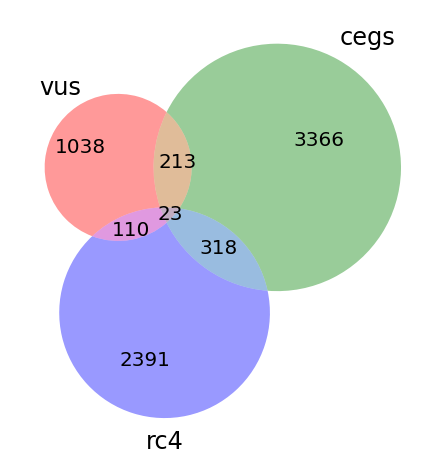

In [64]:
venn3([set(alleles[~alleles.vus_mut_id.isnull()].change),
       set(alleles[~alleles.cegs_mut_id.isnull()].change),
       set(alleles[~alleles.rc4_mut_id.isnull()].change)
      ],['vus','cegs','rc4']);